In [24]:
#Import libraries
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [45]:
#enter B and V vals of reference star  -- CHANGE FOR EACH CLUSTER
# M15 
# REF_B_MAG = 10.928
# REF_V_MAG = 10.378

# M52
# REF_B_MAG = 11.010
# REF_V_MAG = 10.430

# M39
REF_B_MAG = 11.637
REF_V_MAG = 10.409

# file = r"m15.csv"
# file = r"m52.csv"
file = r"m39.csv"

In [46]:
# Assign data to pandas dataframe.
df = pd.read_csv(file, sep = "\t")

#remove unwanted cols
def KeepColumns(colName):
    if (colName[0:10] == 'rel_flux_T' or colName == 'Label'):
        return True
    else:
        return False

In [47]:
df

,,Label,J.D.-2400000,JD_UTC,rel_flux_C1,rel_flux_T2,rel_flux_T3,rel_flux_T4,rel_flux_T5,rel_flux_T6,...,rel_flux_err_T27,rel_flux_err_T28,rel_flux_err_T29,rel_flux_err_T30,rel_flux_err_T31,rel_flux_err_T32,rel_flux_err_T33,rel_flux_err_T34,rel_flux_err_T35,rel_flux_err_T36
0,1,16_PIRATE_54072_OSL_M39_OPEN_00_M39_00_Filter_...,61342.401234,2.461342e+06,0.0,0.497510,0.809304,6.334545,0.662243,18.565445,...,0.012357,0.045029,0.005343,0.025055,0.009851,0.007171,0.194673,0.010159,0.007879,0.006122
1,2,16_PIRATE_54089_OSL_M39_OPEN_00_M39_00_Filter_...,61342.408961,2.461342e+06,0.0,0.201509,0.301247,1.953985,0.442781,4.977321,...,0.002367,0.005286,0.001189,0.003630,0.001901,0.002154,0.016674,0.002130,0.001623,0.001329


In [48]:
#drop unwanted cols
df = pd.read_csv(file, sep = "\t", usecols = KeepColumns)

# Extract B or V from the filename and change the name of the Label
df["Label"] = df["Label"].str.extract(
    r"Filter_([BV])",
    expand=False
)

df

,Label,rel_flux_T2,rel_flux_T3,rel_flux_T4,rel_flux_T5,rel_flux_T6,rel_flux_T7,rel_flux_T8,rel_flux_T9,rel_flux_T10,...,rel_flux_T27,rel_flux_T28,rel_flux_T29,rel_flux_T30,rel_flux_T31,rel_flux_T32,rel_flux_T33,rel_flux_T34,rel_flux_T35,rel_flux_T36
0,B,0.497510,0.809304,6.334545,0.662243,18.565445,14.206898,7.691655,34.907141,10.891636,...,1.646924,7.047487,0.309478,3.773310,1.203328,0.704737,31.414138,1.265696,0.843379,0.492239
1,V,0.201509,0.301247,1.953985,0.442781,4.977321,4.143270,2.392909,7.859713,3.231309,...,0.692762,2.062859,0.134277,1.285351,0.469969,0.591297,7.406969,0.581730,0.340641,0.204536


In [49]:
#set Label col as index
df.set_index('Label', inplace = True)

In [50]:
#transpose from columns to rows 
df = df.transpose()

#Add new column Flux Ratio
df['flux_ratio'] = df['B']/df['V']
df

Label,B,V,flux_ratio
rel_flux_T2,0.497510,0.201509,2.468922
rel_flux_T3,0.809304,0.301247,2.686513
rel_flux_T4,6.334545,1.953985,3.241860
rel_flux_T5,0.662243,0.442781,1.495645
rel_flux_T6,18.565445,4.977321,3.730008
rel_flux_T7,14.206898,4.143270,3.428910
rel_flux_T8,7.691655,2.392909,3.214353
rel_flux_T9,34.907141,7.859713,4.441274
rel_flux_T10,10.891636,3.231309,3.370658
rel_flux_T11,12.434755,3.596461,3.457498


# Calculate magnitudes and plot CMD

In [51]:
#set size of plots
plt.rcParams['figure.figsize'] = [12,8]

need to convert relative flux into apparent mags using below eqn but rearranged

\begin{equation}
m_1 - m_2 = -2.5 \log_{10} \left(\dfrac{F_1}{F_2}\right)  \tag{2.1b}
\end{equation}

In [52]:
# Calculate apparent magnitudes for each star and B-V index
df['Bmag'] = -2.5*np.log10(df['B']) + REF_B_MAG
df['Vmag'] = -2.5*np.log10(df['V']) + REF_V_MAG
df['B_V'] = df['Bmag'] - df['Vmag']
df.head(3)

Label,B,V,flux_ratio,Bmag,Vmag,B_V
rel_flux_T2,0.497510,0.201509,2.468922,12.394995,12.148264,0.246732
rel_flux_T3,0.809304,0.301247,2.686513,11.866721,11.711693,0.155028
rel_flux_T4,6.334545,1.953985,3.241860,9.632711,9.681697,-0.048986


In [53]:
#Remove stars that are extremely red - NOT part of cluster these are BG stars.
# Calculate a colour index: subtract apparent magnitude in one filter from another (REDDER filter subtracted from BLUER (B-V)
# Lower V mag = brighter star and high B-V value = redder star (dimmer in the blue)

# want to remove all stars with B-V val > 2.0
data = df[df['B_V'] < 2.0].copy()

print("Number of stars remaining:", len(data), "out of", len(df))

Number of stars remaining: 35 out of 35


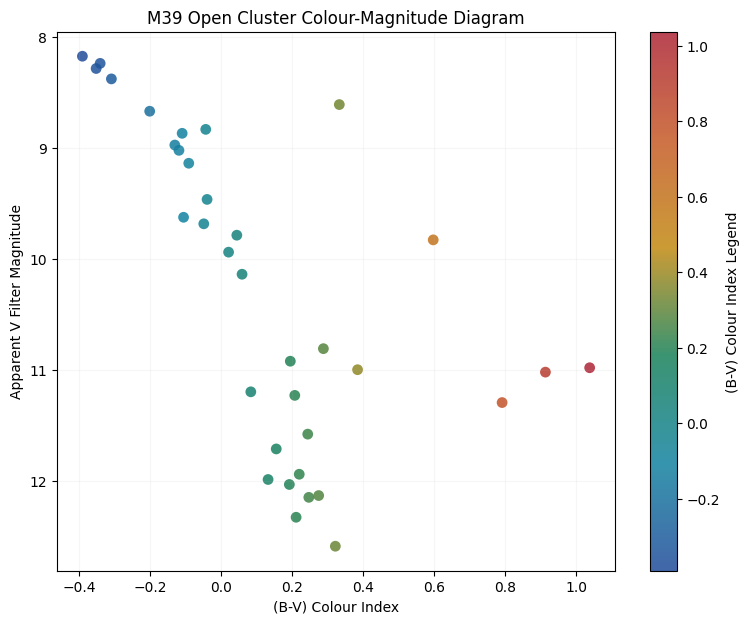

In [54]:
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize=(9, 7))

my_cmap = LinearSegmentedColormap.from_list(
    "deep_spectrum",
    [
        "#214c9a",  # Deep blue
        "#1383a0",  # Teal
        "#188258",  # Forest green
        "#c28a12",  # Golden amber
        "#c65a27",  # Orange
        "#ad2536"   # Deep red
    ]
)

plt.scatter(
    data["B_V"],
    data["Vmag"],
    c=data["B_V"],
    cmap=my_cmap,
    edgecolors = 'black',
    linewidths=0,
    s=60,
    alpha=0.85
)

# Automatically scale axes, but reverse Y for magnitude
plt.gca().invert_yaxis()

# plt.title("M15 Globular Cluster Colour-Magnitude Diagram")
# plt.title("M52 Open Cluster Colour-Magnitude Diagram")
plt.title("M39 Open Cluster Colour-Magnitude Diagram")
plt.xlabel("(B-V) Colour Index")
plt.ylabel("Apparent V Filter Magnitude")
plt.colorbar(label="(B-V) Colour Index Legend")
plt.grid(alpha=0.1)

# Save chart as PNG (high resolution)
# plt.savefig("M15_CMD.png", dpi=300, bbox_inches="tight")
# plt.savefig("M52_CMD.png", dpi=300, bbox_inches="tight")
plt.savefig("M39_CMD.png", dpi=300, bbox_inches="tight")

plt.show()

# Looking at E(B-V)

In [31]:
# Colour Excess E(B-V) for cluster
colour_excess = 0.01

In [32]:
# Filtering the data to look at stars with a colour excess in the specified range above for each cluster
data = data.sort_values(by='Vmag', ascending=True) 

ranges = data[(data['B_V'] >= 0.005) & (data["B_V"] <= 0.05)] #change these depending on cluster
ranges

Label,B,V,flux_ratio,Bmag,Vmag,B_V
rel_flux_T25,5.506091,1.826361,3.014788,9.784892,9.755033,0.029858
rel_flux_T13,3.857036,1.278676,3.016429,10.171366,10.142099,0.029267


In [33]:
# Chossing associated Vmag closest to the colour excess
vmag = 10.142009

In [34]:
#interstellar exctinction is given by 3E(B-V)
a_v = 3*colour_excess

In [35]:
# Absolute V magnitude of an A0 main sequence star is given as
a0_m_v = 0.70

# Calculate distance in parsecs
d_pc = 10 ** ((vmag - a0_m_v + 5 - a_v) / 5)

print(f"Distance = {d_pc:.2f} pc")

Distance = 762.78 pc


In [37]:
#estimating uncertainty
mean = (9.755033+10.142009)/2
print(mean)

9.948521


In [38]:
std =ranges['Vmag'].std()

print(std)

#M52 STDEV = 1.3104580416872567

0.2736964822762308


In [39]:
print(f"uncertainty = {mean:.2f} ± {std:.2f} mag")# scatter-based uncertainty estimate

uncertainty = 9.95 ± 0.27 mag


In [40]:
mag_uncertainty = ranges['Vmag'].std()

# Propagate magnitude uncertainty into distance
distance_uncertainty = (np.log(10) / 5) * d_pc * mag_uncertainty

# Display results
print(f"Magnitude uncertainty = {mag_uncertainty:.3f} mag")
print(f"Distance = {d_pc:.0f} ± {distance_uncertainty:.0f} pc")

Magnitude uncertainty = 0.274 mag
Distance = 763 ± 96 pc
